# 13 - Build dashboards 6 to 10

This notebook rebuilds the five dashboards from the scripts in `dashboards/` and shows each one underneath.

| Dashboard | Script | Based on notebook |
|---|---|---|
| D06 Routing | `d06_routing.py` | 09_routing |
| D07 Duration | `d07_duration.py` | 10_duration |
| D08 Bank network | `d08_network.py` | 11_network |
| D09 Party details | `d09_party_details.py` | 12_details_tokens |
| D10 Consistency | `d10_consistency.py` | 08_consistency |

- Each script runs as its own process, exactly as `python dashboards/<script>.py` would from a terminal. That keeps the notebook's memory free and avoids import-path problems.
- Output: `reports/dashboards/D06_routing.pdf` and `.png`, and so on.
- Time: about 1-2 minutes per dashboard. D09 takes a few minutes the first time, because it builds its working tables (it reuses notebook 12's tables if they already exist).
- You can run a single dashboard's cell on its own after running the setup cell.

Run the cells top to bottom.

In [1]:
import subprocess
import sys
import time
from pathlib import Path

from IPython.display import Image, display

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "dashboards").exists():
    ROOT = ROOT.parent
assert (ROOT / "dashboards" / "dash_style.py").exists(), f"Project root not found from {Path.cwd()}"

OUT_DIR = ROOT / "reports" / "dashboards"


def build(script, picture):
    """Run one dashboard script with this notebook's Python, then show the saved picture."""
    path = ROOT / "dashboards" / script
    assert path.exists(), f"Missing script: {path}"
    start = time.time()
    result = subprocess.run([sys.executable, str(path)], cwd=ROOT, capture_output=True, text=True)
    if result.stdout.strip():
        print(result.stdout.strip())
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"{script} failed (exit code {result.returncode}); the error is printed above")
    png = OUT_DIR / f"{picture}.png"
    assert png.exists(), f"The script finished but {png} was not found"
    print(f"{script}: done in {time.time() - start:.0f} s")
    display(Image(filename=str(png)))


print(f"Project root: {ROOT}")
print(f"Python used for the dashboards: {sys.executable}")

Project root: c:\Universiti Malaya (Extra)\DATATHON\liqi-datathon
Python used for the dashboards: c:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\.venv\Scripts\python.exe


## D06 Routing

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC
Saved C:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\reports\dashboards\D06_routing.pdf and .png
d06_routing.py: done in 13 s


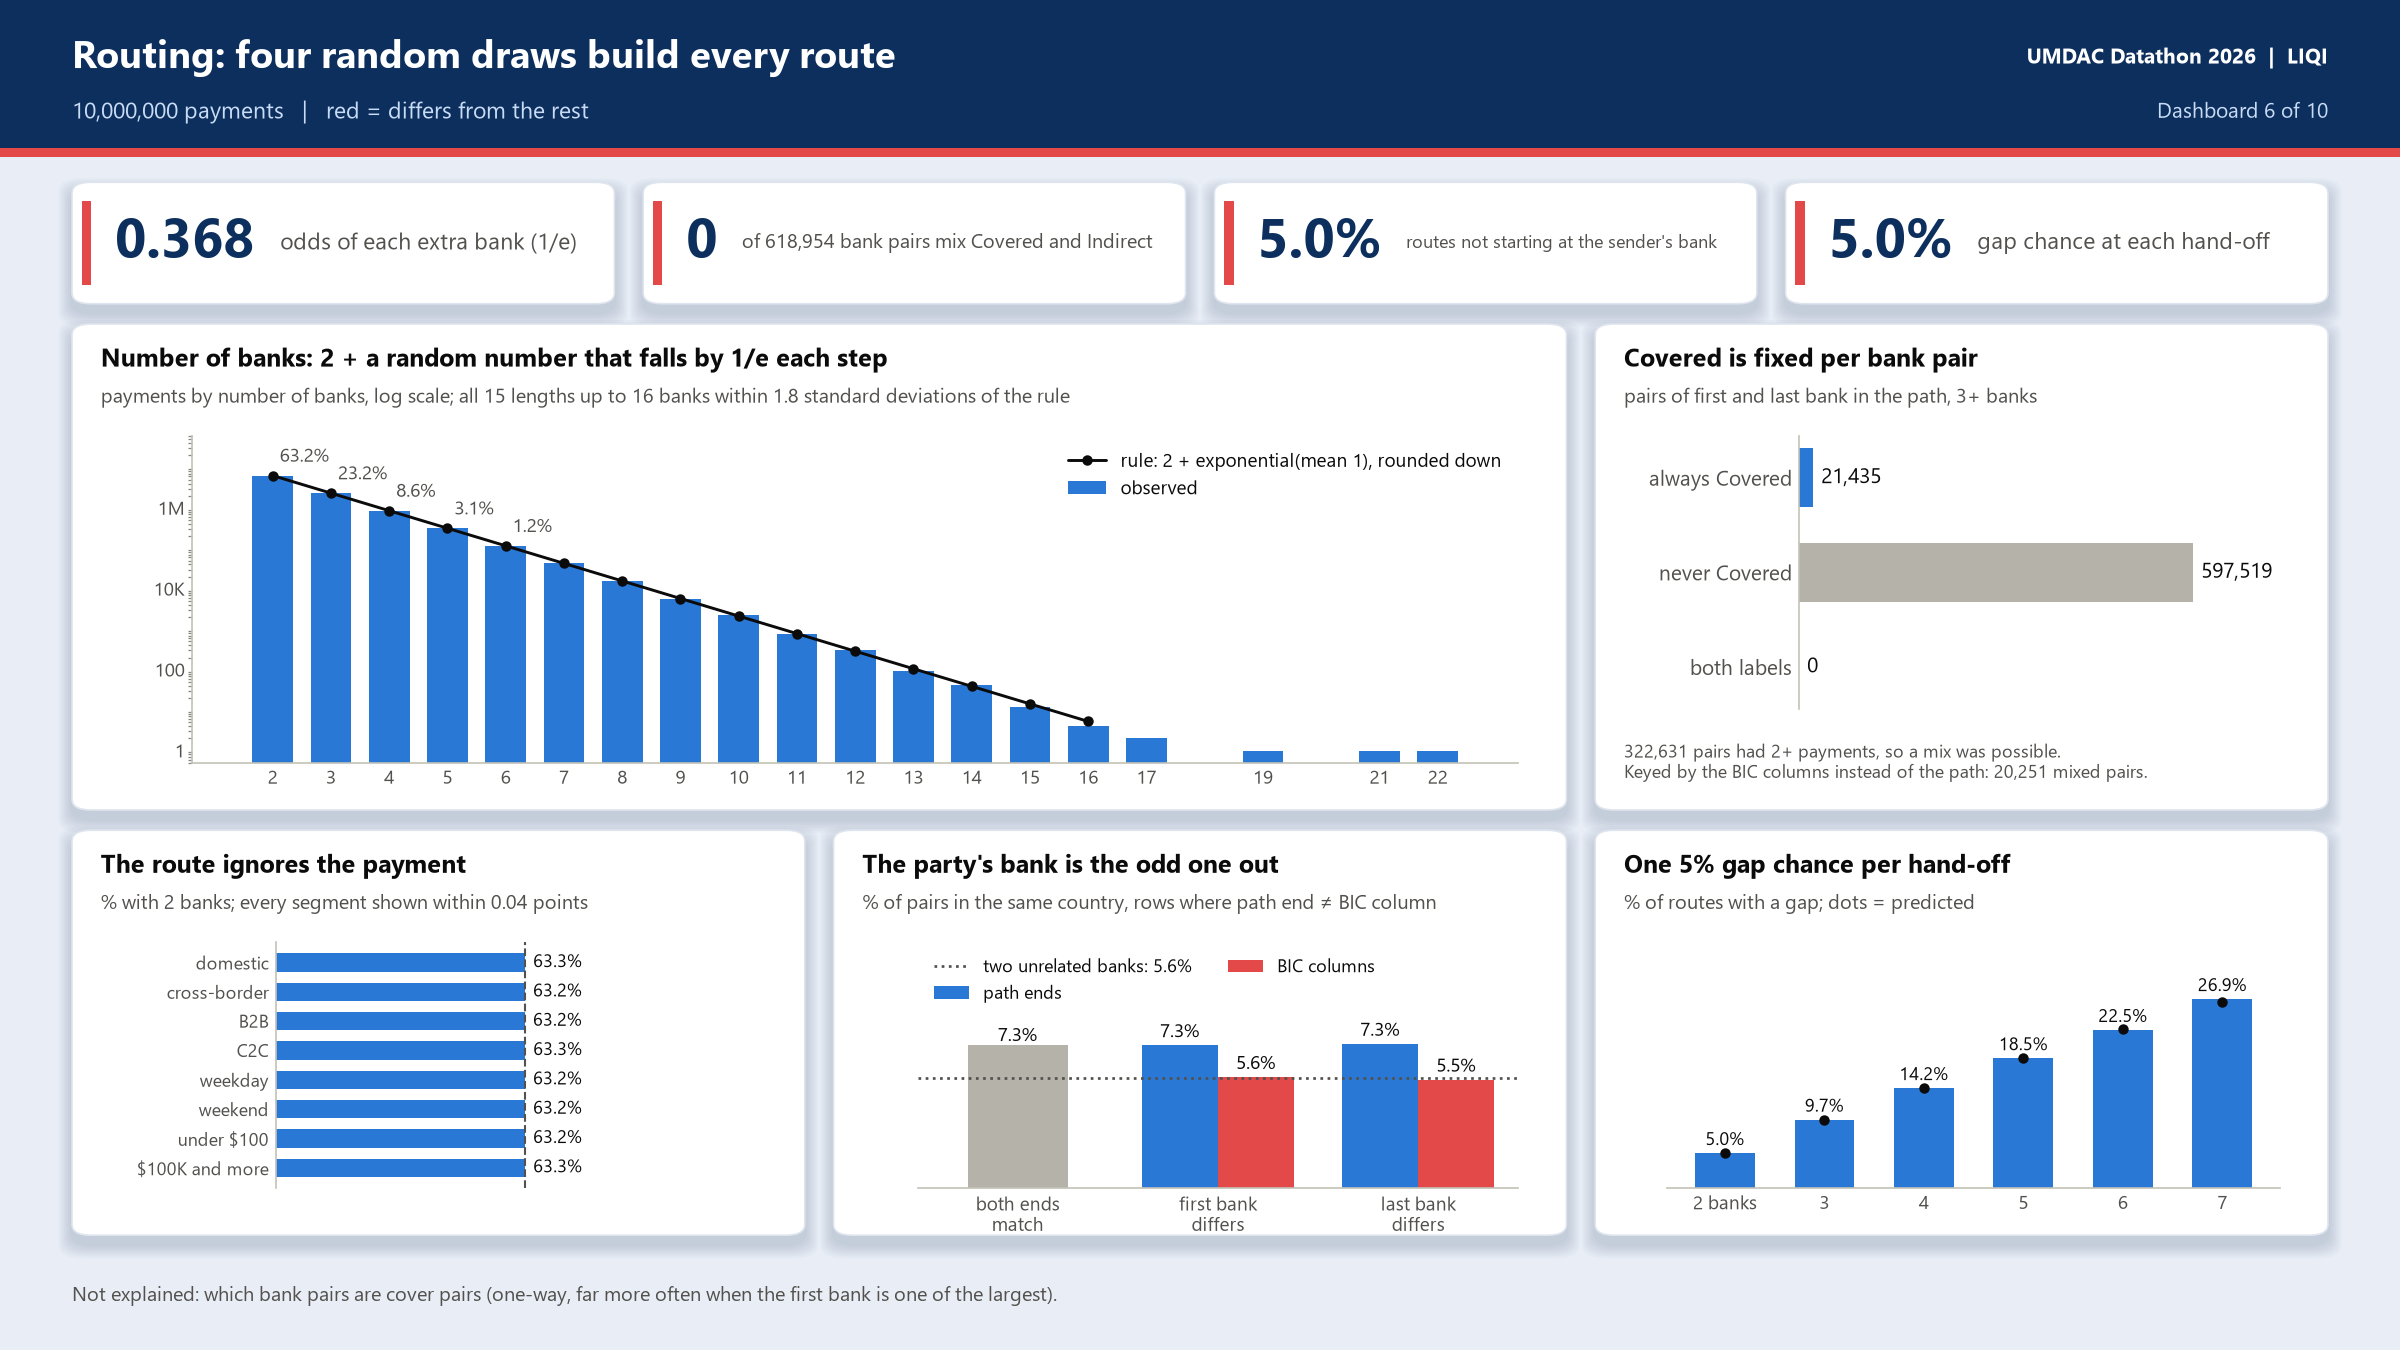

In [2]:
build("d06_routing.py", "D06_routing")

## D07 Duration

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC
Saved C:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\reports\dashboards\D07_duration.pdf and .png
d07_duration.py: done in 8 s


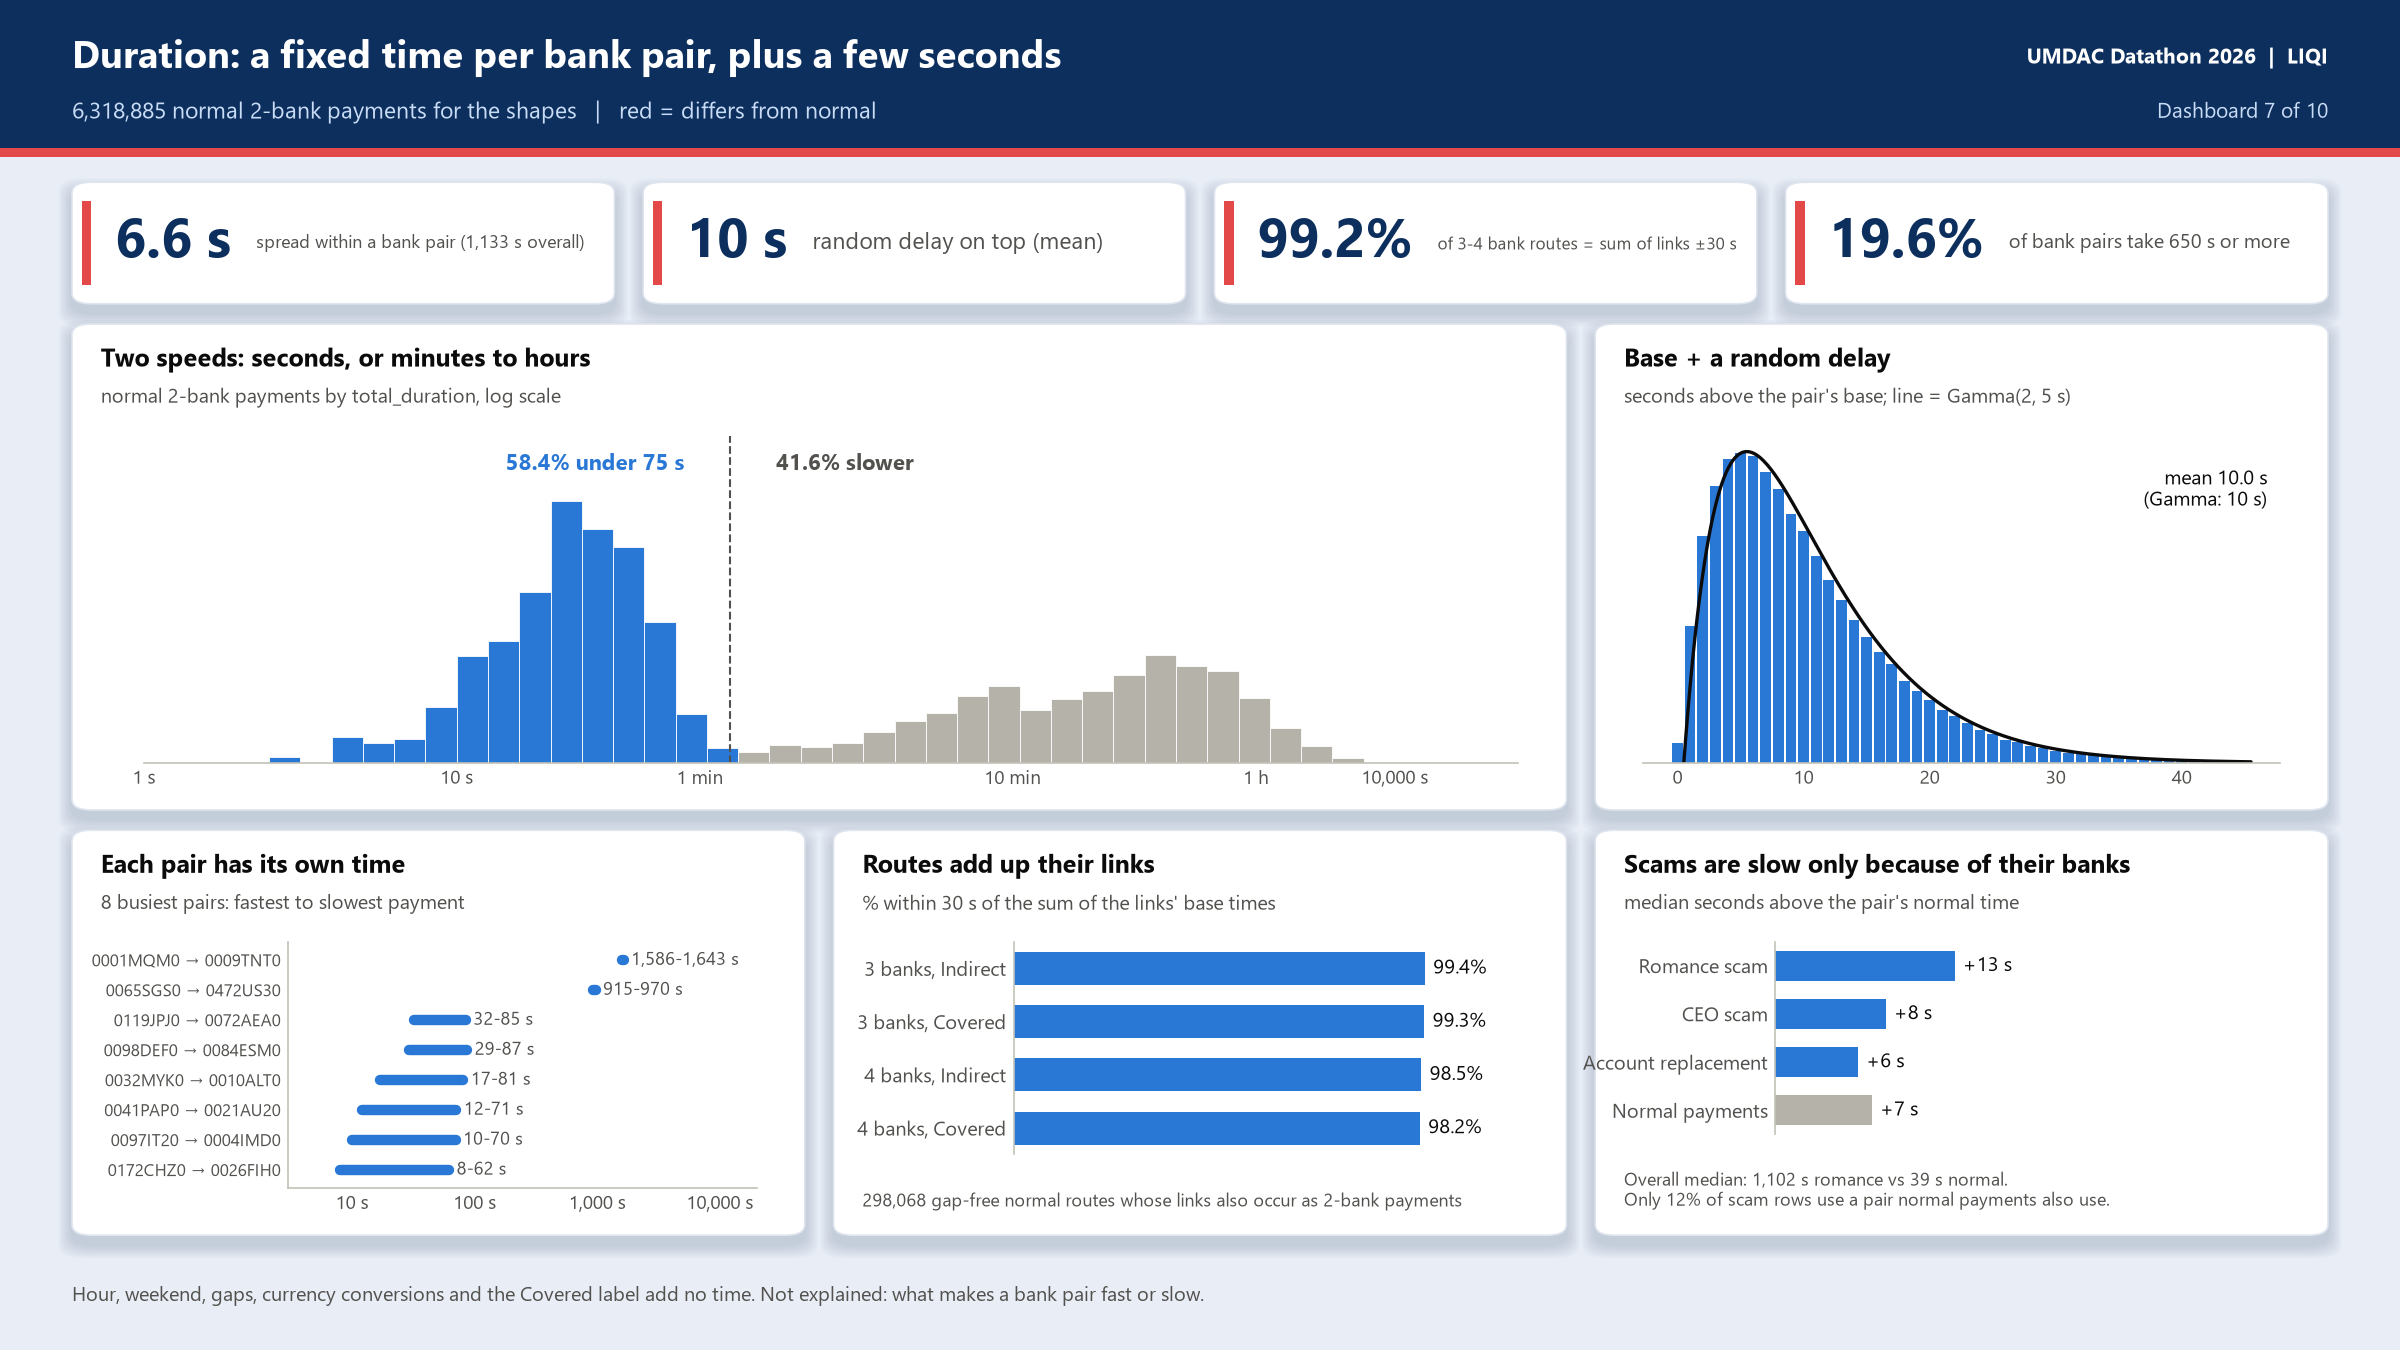

In [3]:
build("d07_duration.py", "D07_duration")

## D08 Bank network

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC
Saved C:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\reports\dashboards\D08_network.pdf and .png
d08_network.py: done in 11 s


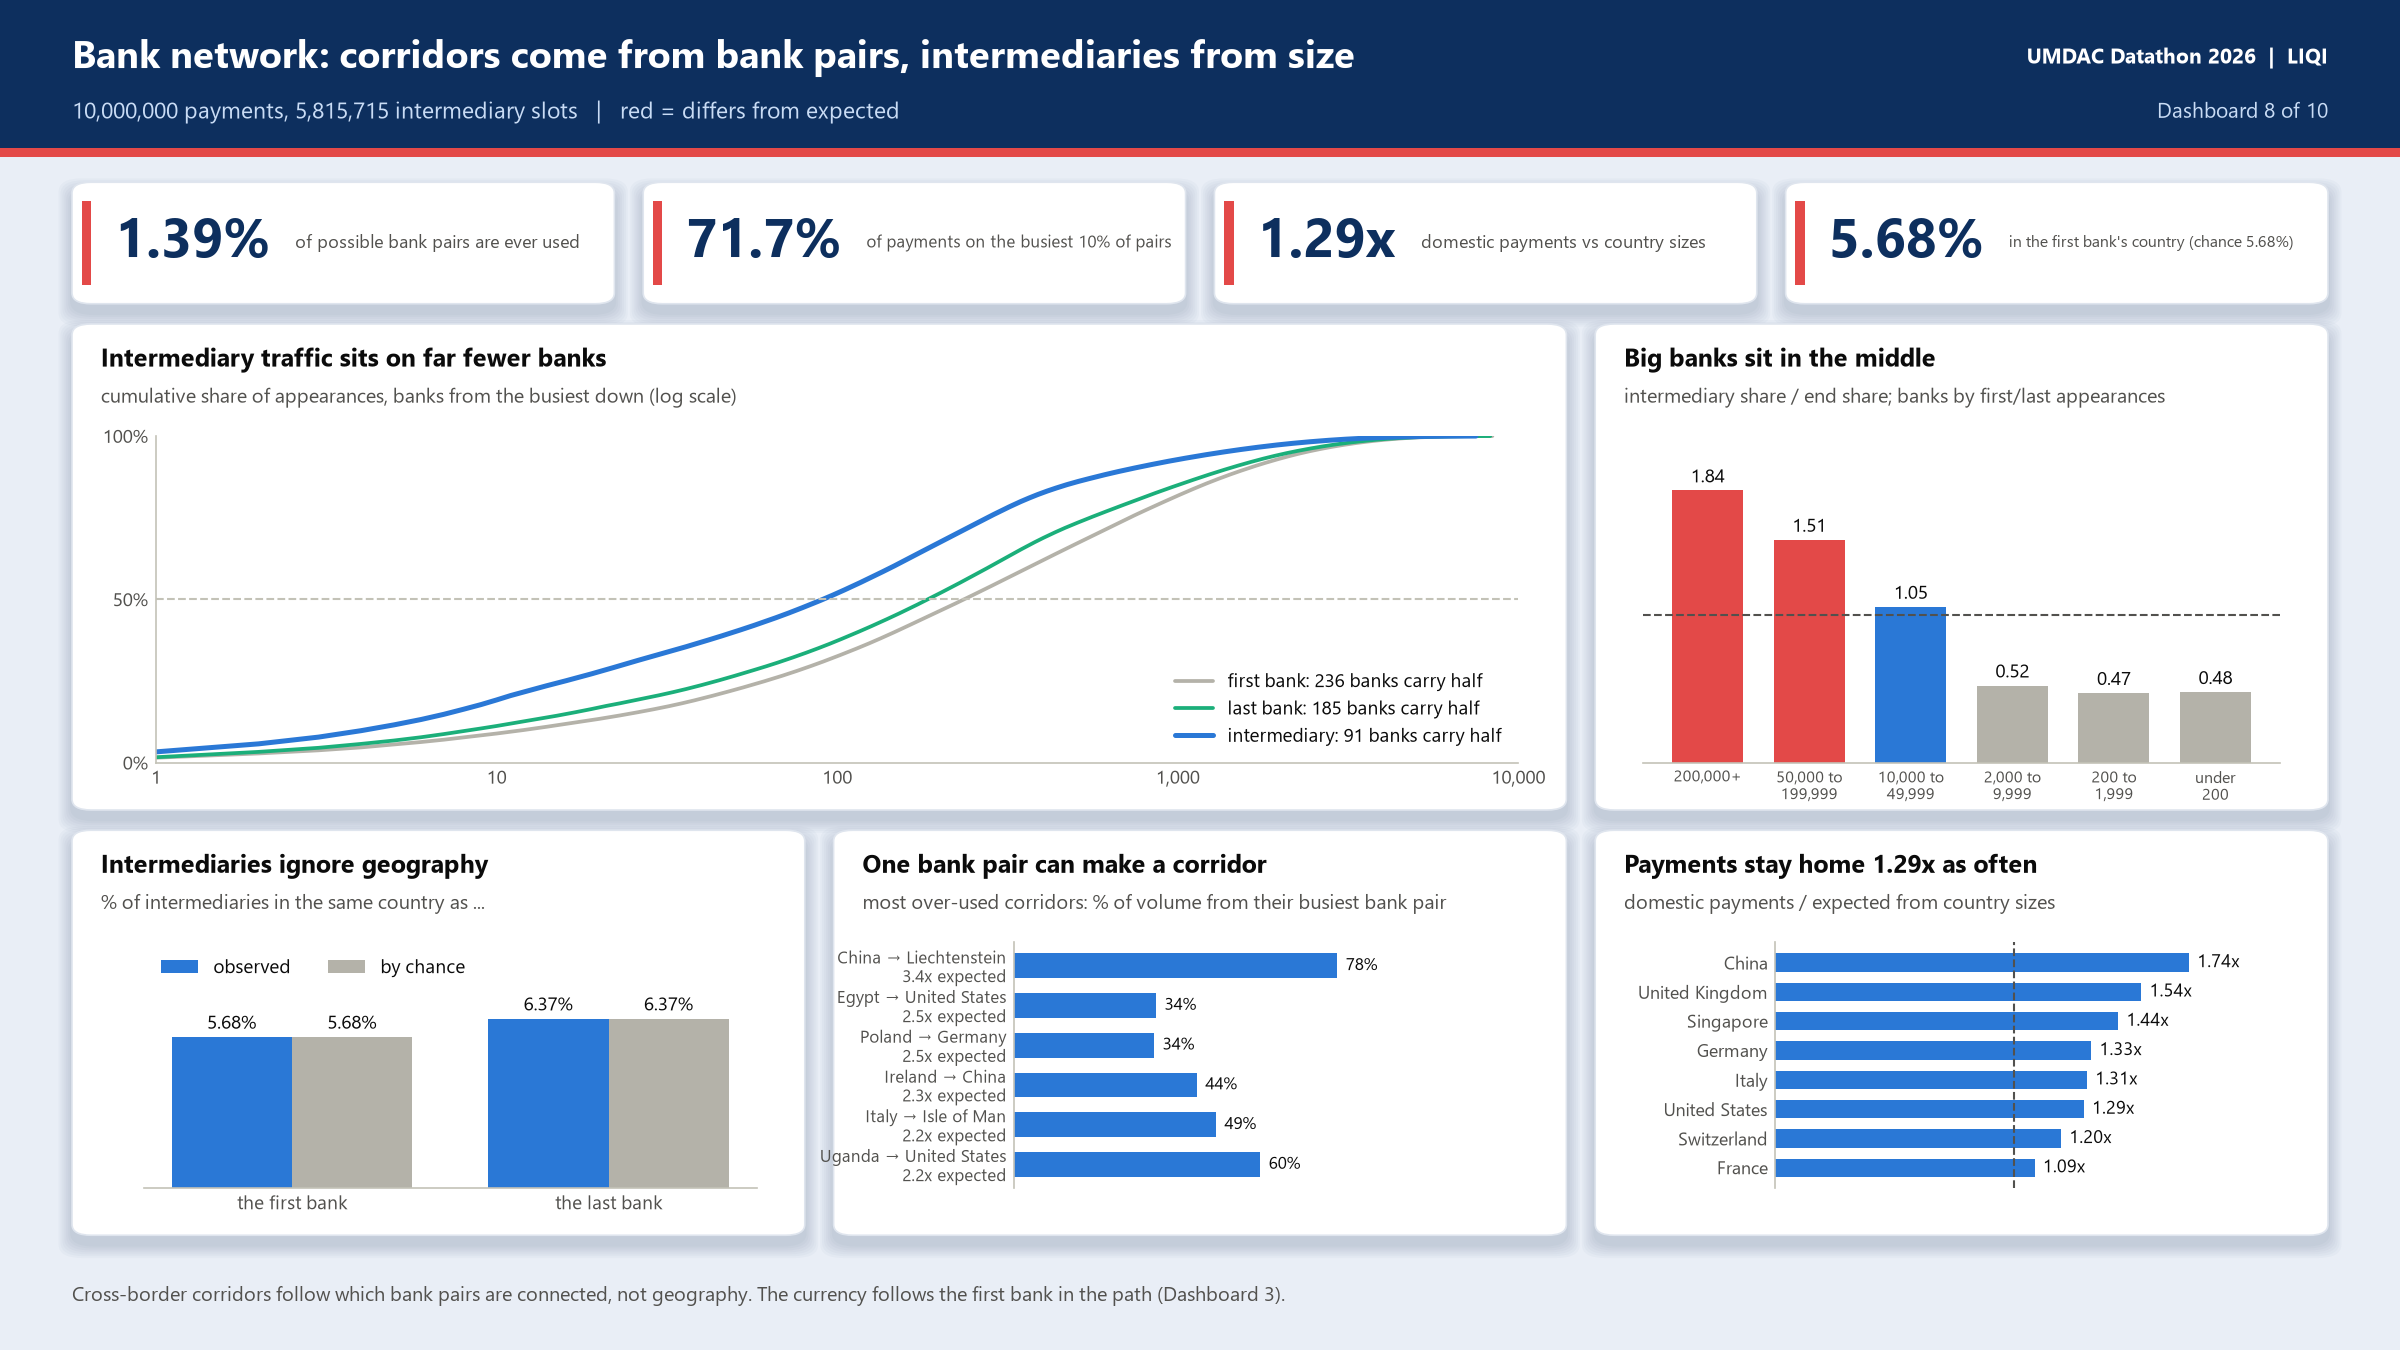

In [4]:
build("d08_network.py", "D08_network")

## D09 Party details

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC
Building dash_party_sender (first run only) ...
Building dash_party_receiver (first run only) ...
Saved C:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\reports\dashboards\D09_party_details.pdf and .png
d09_party_details.py: done in 40 s


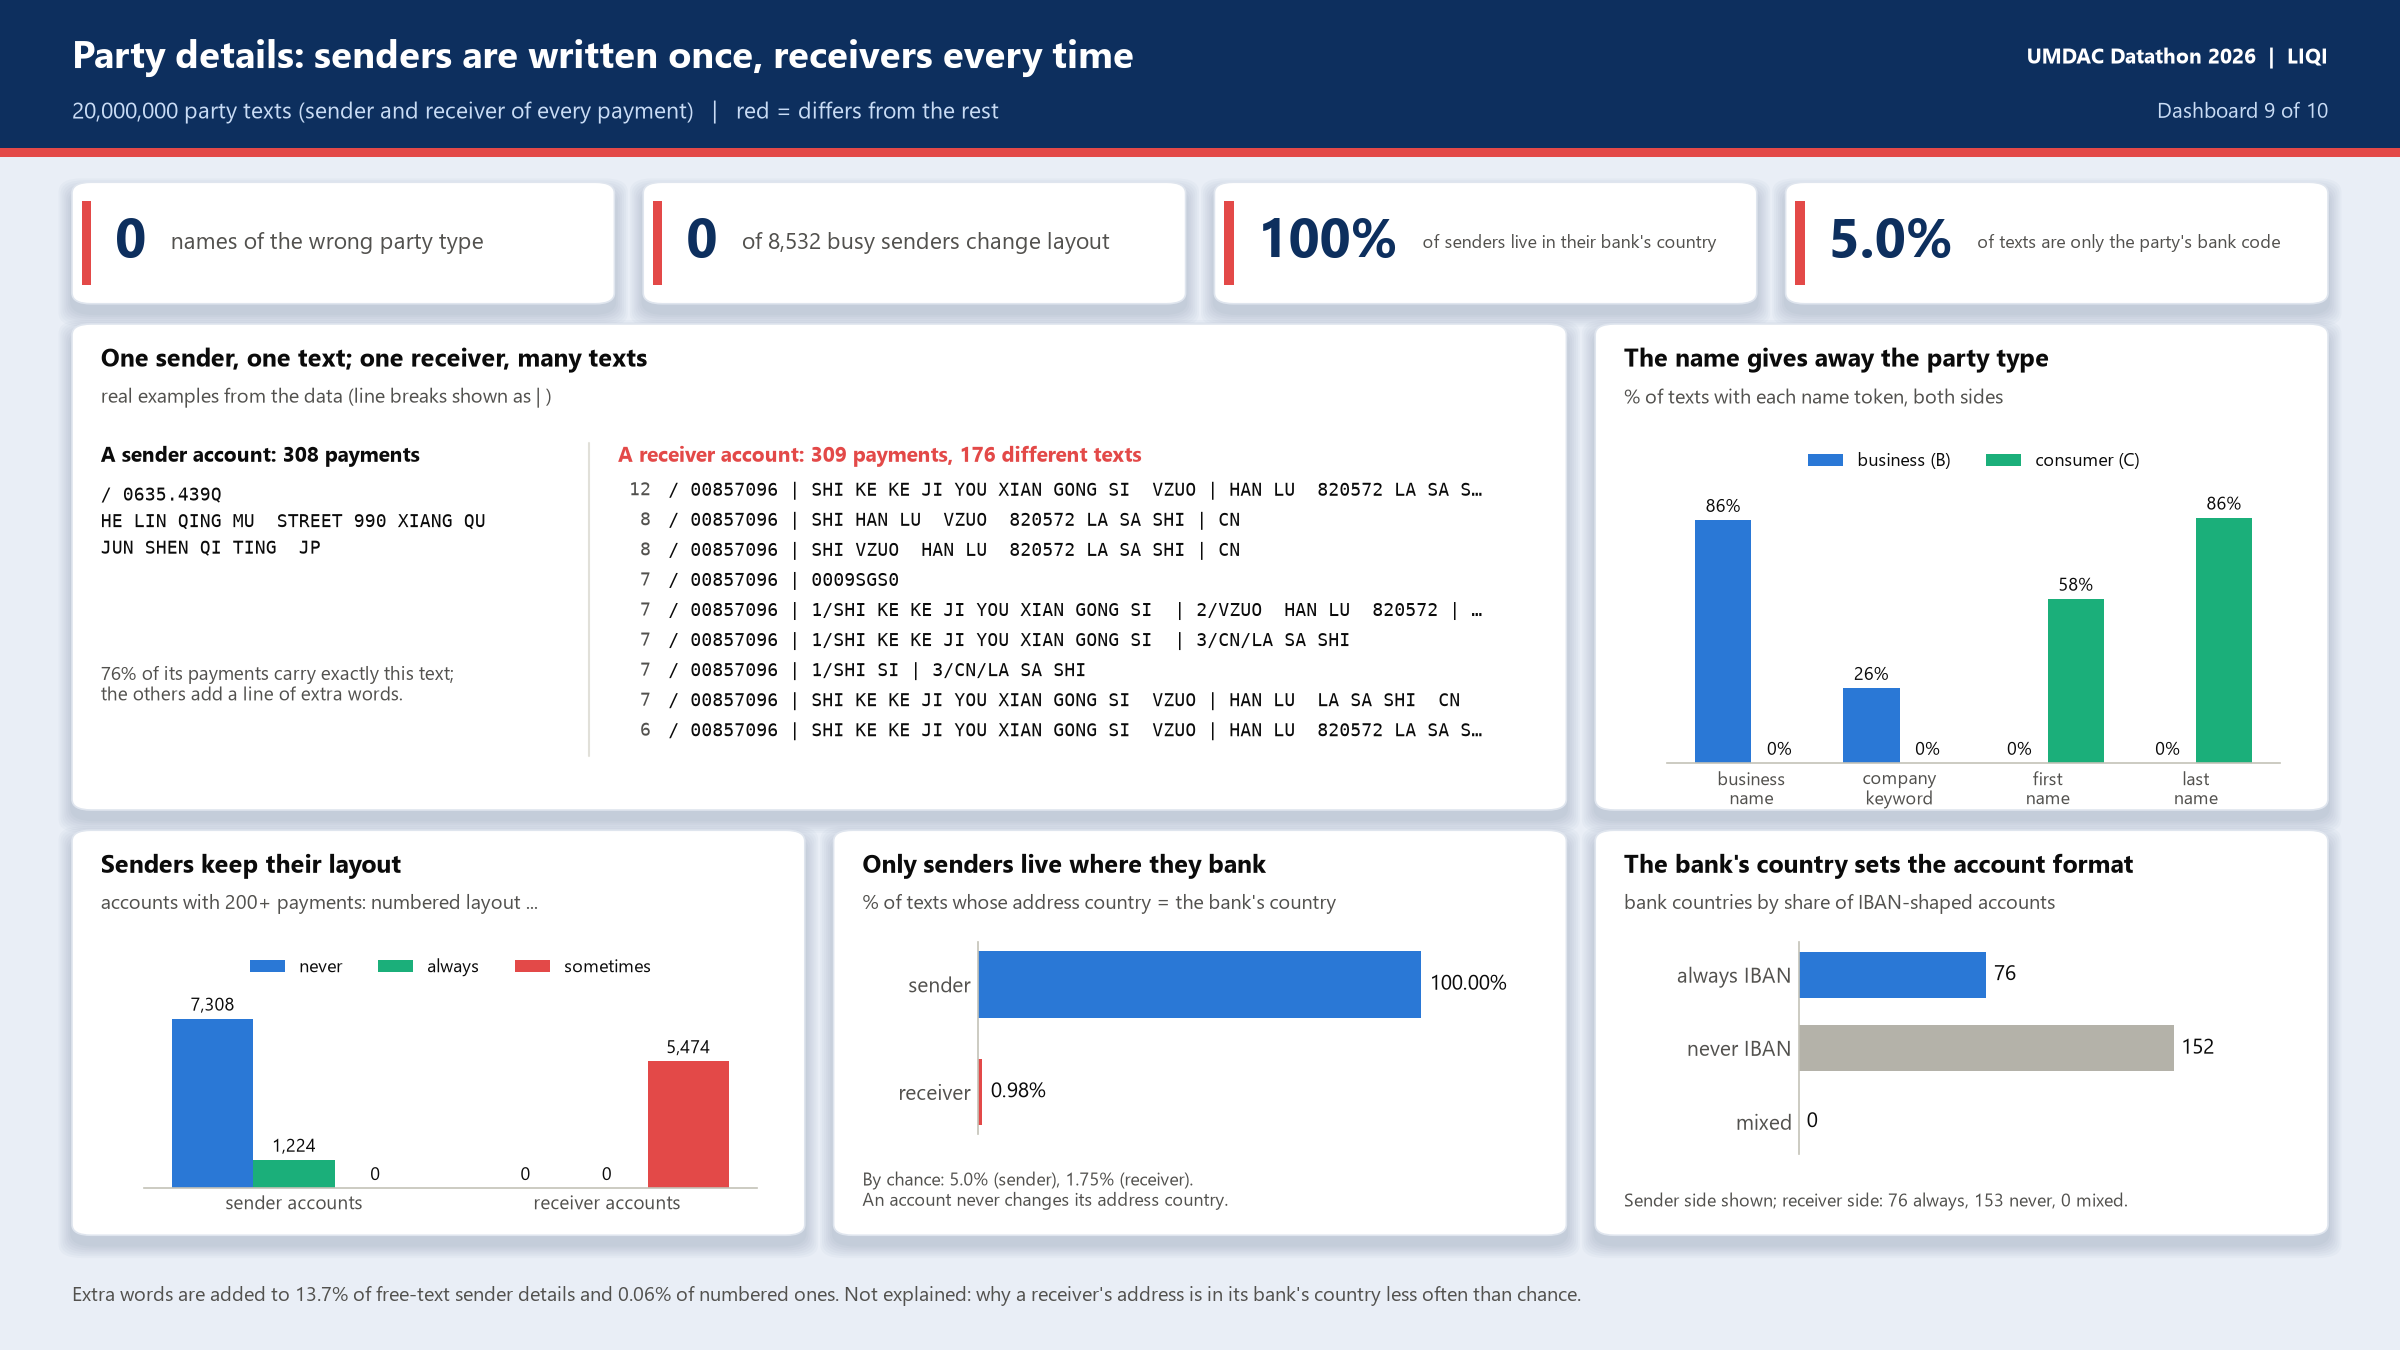

In [5]:
build("d09_party_details.py", "D09_party_details")

## D10 Consistency

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC
Saved C:\Universiti Malaya (Extra)\DATATHON\liqi-datathon\reports\dashboards\D10_consistency.pdf and .png
d10_consistency.py: done in 36 s


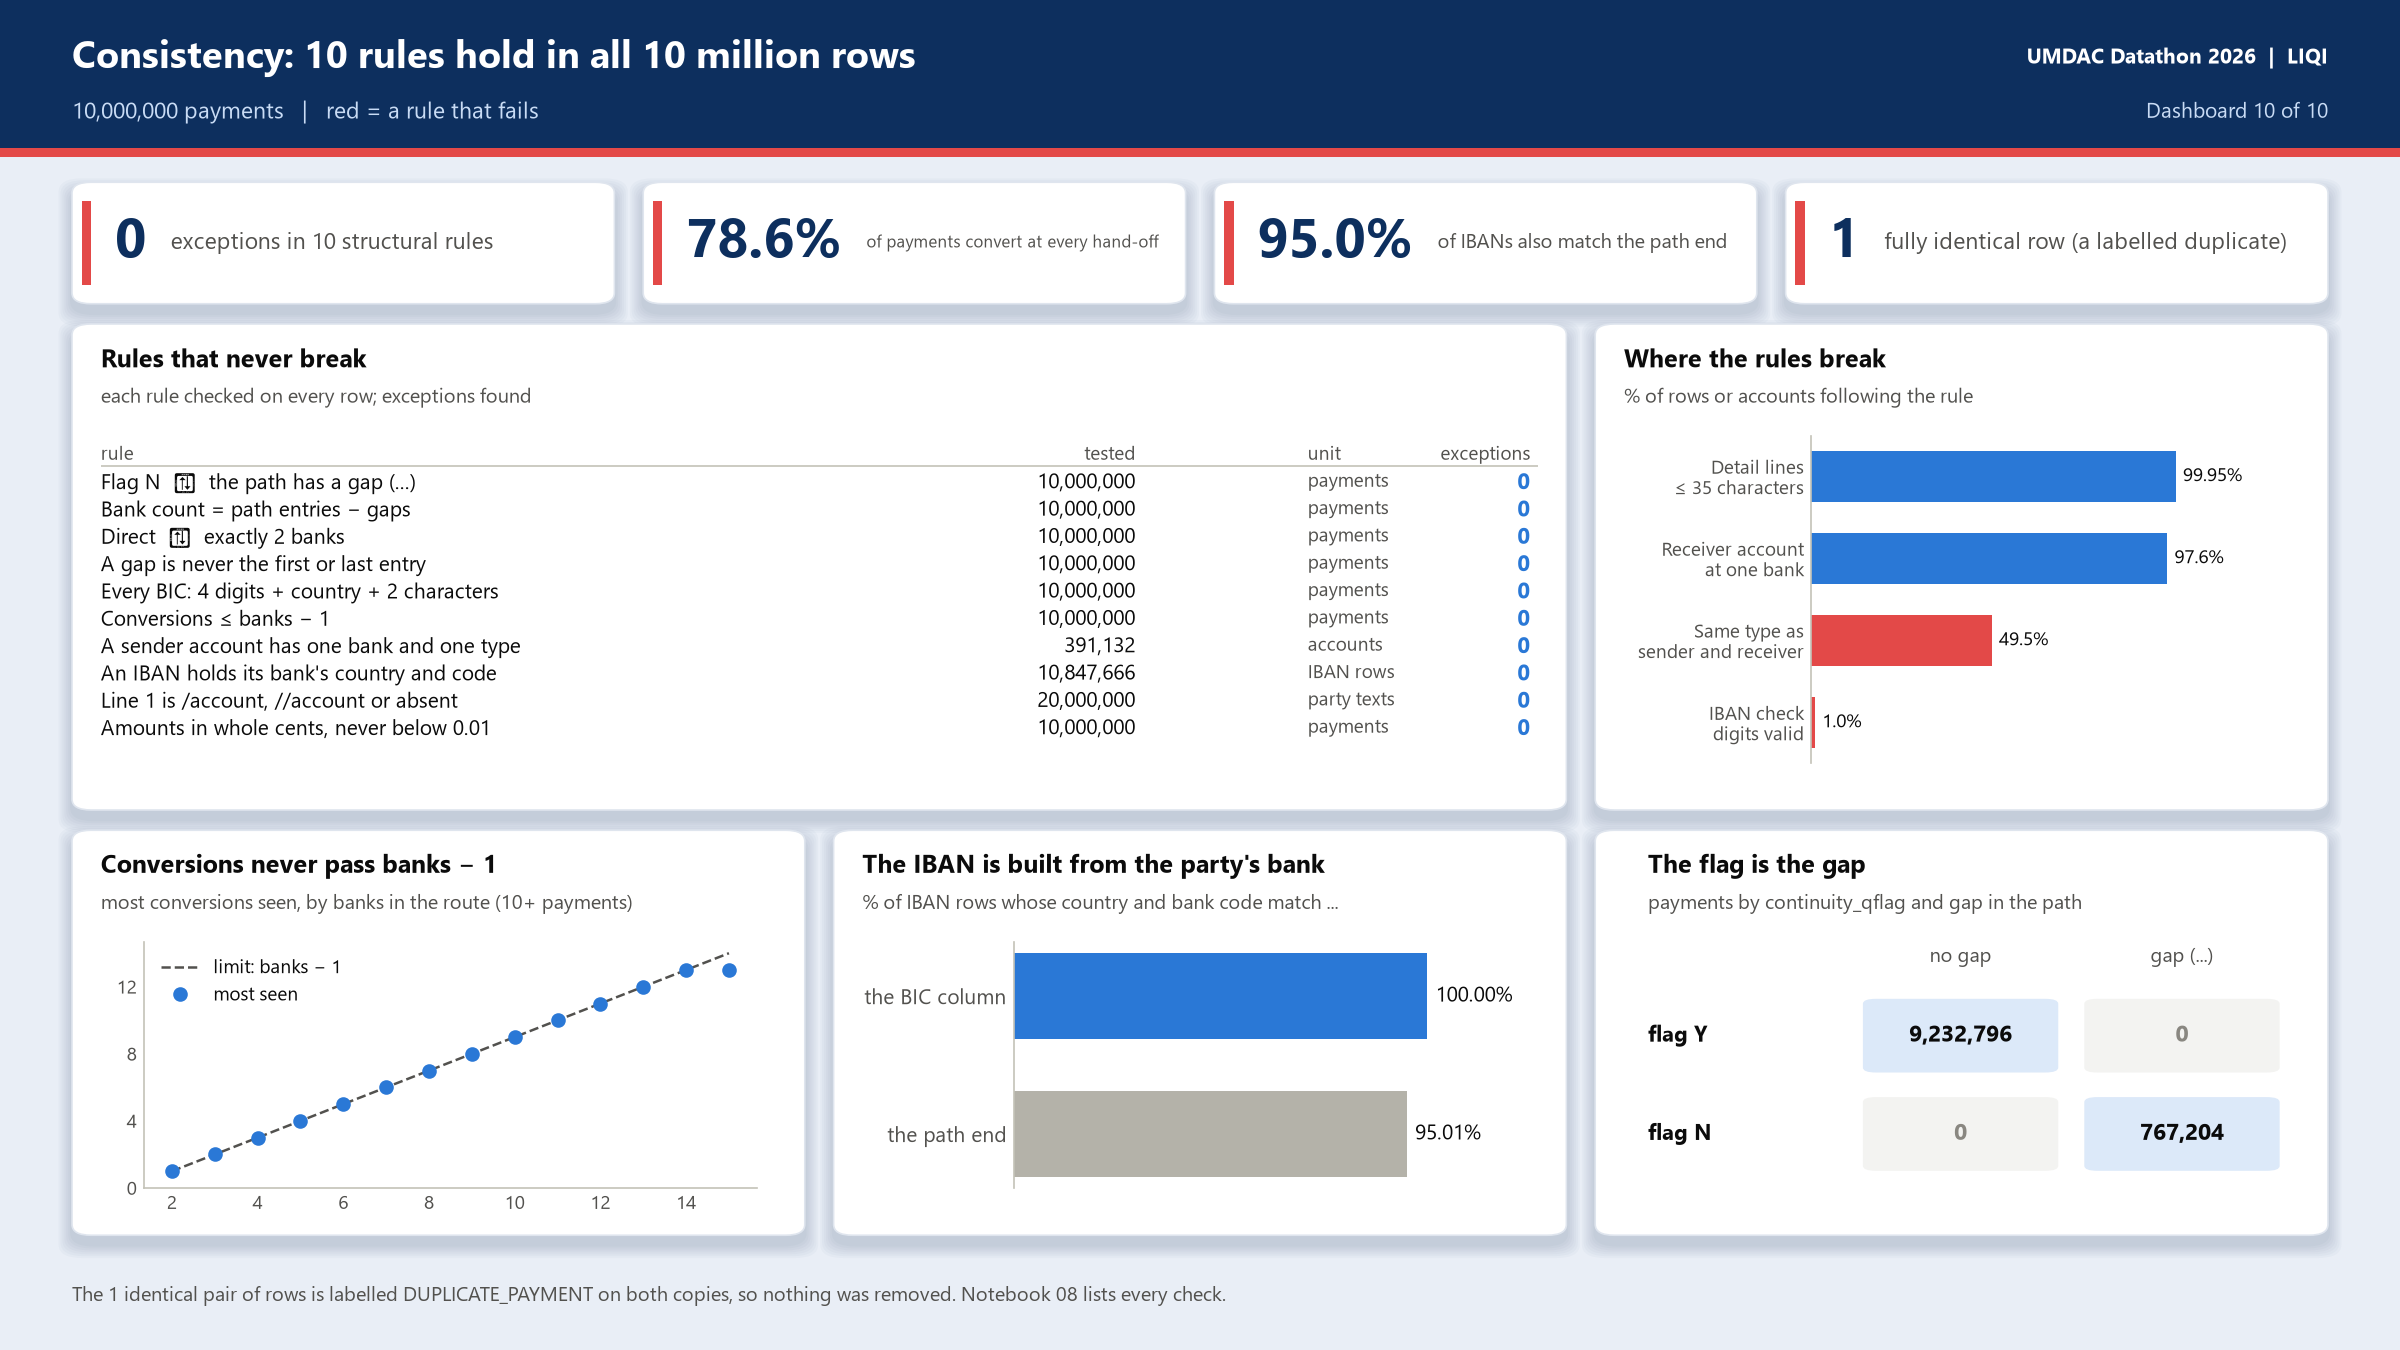

In [6]:
build("d10_consistency.py", "D10_consistency")

## Check: all five files are there

Lists the PDF and PNG of each dashboard with its size and the time it was last saved.

In [7]:
names = ["D06_routing", "D07_duration", "D08_network", "D09_party_details", "D10_consistency"]
for name in names:
    for ext in ("pdf", "png"):
        f = OUT_DIR / f"{name}.{ext}"
        if f.exists():
            print(f"{f.name:<26} {f.stat().st_size / 1024:>7.0f} KB   saved {time.strftime('%Y-%m-%d %H:%M', time.localtime(f.stat().st_mtime))}")
        else:
            print(f"{f.name:<26} MISSING")

D06_routing.pdf                 54 KB   saved 2026-11-19 00:10
D06_routing.png                261 KB   saved 2026-11-19 00:10
D07_duration.pdf                56 KB   saved 2026-11-19 00:10
D07_duration.png               253 KB   saved 2026-11-19 00:10
D08_network.pdf                 54 KB   saved 2026-11-19 00:11
D08_network.png                278 KB   saved 2026-11-19 00:11
D09_party_details.pdf           57 KB   saved 2026-11-19 00:11
D09_party_details.png          282 KB   saved 2026-11-19 00:11
D10_consistency.pdf             65 KB   saved 2026-11-19 00:12
D10_consistency.png            273 KB   saved 2026-11-19 00:12
